In [1]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import *
# import geopandas as gpd

In [2]:
# Goal: Generate metadata and FASTA files for a dataset that just corresponds to live/harvested detections

In [3]:
# Upload the detections data

FILE1 = "./metadata/detections_data/combinedNAm_detections_2021-2025.csv"

full_NAm_detections = pd.read_csv(FILE1, sep = ",")

In [4]:
print(full_NAm_detections.columns)

Index(['Unnamed: 0', 'Collection Date', 'Location', 'Avian_Host', 'Country',
       'Flyway', 'Latitude_Group', 'Host_Order', 'Host_Broad', 'Sample_Method',
       'Corrected_Avian_Host'],
      dtype='object')


In [5]:
# Upload the sequencing metadata

FILE2 = "./metadata/sequence_metadata/NCBI-BVBRC_ha_detectionsgeodata.tsv"

metadata = pd.read_csv(FILE2, sep = '\t')

In [6]:
print(metadata.columns)
print(len(metadata))

Index(['Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'genbank_acc',
       'bp_length', 'ncbibvbrc_segment', 'ncbibvbrc_nonambigdate',
       'ncbibvbrc_date', 'ncbibvbrc_strain', 'ncbibvbrc_division',
       'ncbibvbrc_strain_host', 'ncbibvbrc_order', 'ncbibvbrc_domesticstatus',
       'ncbibvbrc_corrected_host', 'ncbibvbrc_flyway', 'ncbibvbrc_statecoord',
       'ncbibvbrc_hostgroup', 'ncbibvbrc_country', 'ncbibvbrc_subtype',
       'bvbrc_assembled', 'strain_segment_updated', 'strain', 'year_only',
       'month_only', 'source', 'Genome ID', 'county', 'city',
       'county_lat-long', 'city_lat-long', 'lat_long_to_use',
       'lat_long_source', 'lat', 'long', 'genoflu_genotype',
       'genoflu_genotype_upt'],
      dtype='object')
5869


In [7]:
# Step one: label each sequence that matches a detection with the sampling method

In [14]:
# Function: what to do when a matching row(s) exists 
# This function is intended as a nesting function inside the next function

def filling_rows_samplingmethod(metadata_sampling, idx, matching_rows):
    
    unique_methods_in_match = set(matching_rows["Sample_Method"].tolist()) # If there are more than one option for sampling method
    
    # if matching rows exist, this function will follow a specific set of instructions
    if len(unique_methods_in_match) == 1: 
        # If there is one matching method, add the method
        metadata_sampling.at[idx, "detection_samplingmethod"] = matching_rows["Sample_Method"].iloc[0]
                    
    # If there is more than one "county" match in matching rows
    elif len(unique_methods_in_match) > 1:
        metadata_sampling.at[idx, "detection_samplingmethod"] = "unknown"

    # If no matching rows are found, set county to "unknown"
    else:
        print(f"Unexpected case (no matching methods) at index {idx}")

    return(metadata_sampling)

In [15]:
# Function: how to detect and fill matching rows

def matching_datehostdivision(metadata, detections):

    metadata_sampling = metadata.copy()
    
    for idx, row in metadata_sampling.iterrows():
        # Find rows in detections_H5N1_newcolumns that match the current row's values
        matching_rows = detections[
            (detections["Collection Date"] == row["ncbibvbrc_date"]) &
            (detections["Location"] == row["ncbibvbrc_division"]) &
            (detections["Corrected_Avian_Host"] == row["ncbibvbrc_corrected_host"])
        ]
        
        # If matching rows exist, assign the corresponding county or value
        if not matching_rows.empty:
            metadata_sampling = filling_rows_samplingmethod(metadata_sampling, idx, matching_rows)
        else: 
            metadata_sampling.at[idx, "detection_samplingmethod"] = "unknown" 

    return(metadata_sampling)

In [16]:
metadata_with_sampling_method = matching_datehostdivision(metadata, full_NAm_detections)

In [17]:
print(metadata_with_sampling_method["detection_samplingmethod"].value_counts())
print(len(metadata_with_sampling_method))

detection_samplingmethod
Dead                     3870
unknown                   889
Agency/Hunter_Harvest     395
Live                      312
Euthanized                 31
Name: count, dtype: int64
5869


In [18]:
# Step two: subset to just live and harvested detections

In [19]:
sampling = ["Agency/Hunter_Harvest", "Live"]

metadata_liveharvest = metadata_with_sampling_method[metadata_with_sampling_method["detection_samplingmethod"].isin(sampling)]
print(len(metadata_liveharvest))

707


In [20]:
# Also subset to just the main introduction
# That means no A3, A4, A5, D1.1, or D1.3

not_mainintro = ["A3", "A4", "A5", "D1.1", "D1.3"]

metadata_liveharvest_mainintro = metadata_liveharvest[~metadata_liveharvest["genoflu_genotype"].isin(not_mainintro)]
print(len(metadata_liveharvest_mainintro))

639


In [21]:
metadata_liveharvest_mainintro["year_month"] = metadata_liveharvest_mainintro["ncbibvbrc_date"].str.split("-", expand = True)[0] + "_" + metadata_liveharvest_mainintro["ncbibvbrc_date"].str.split("-", expand = True)[1]

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_66239/309586710.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


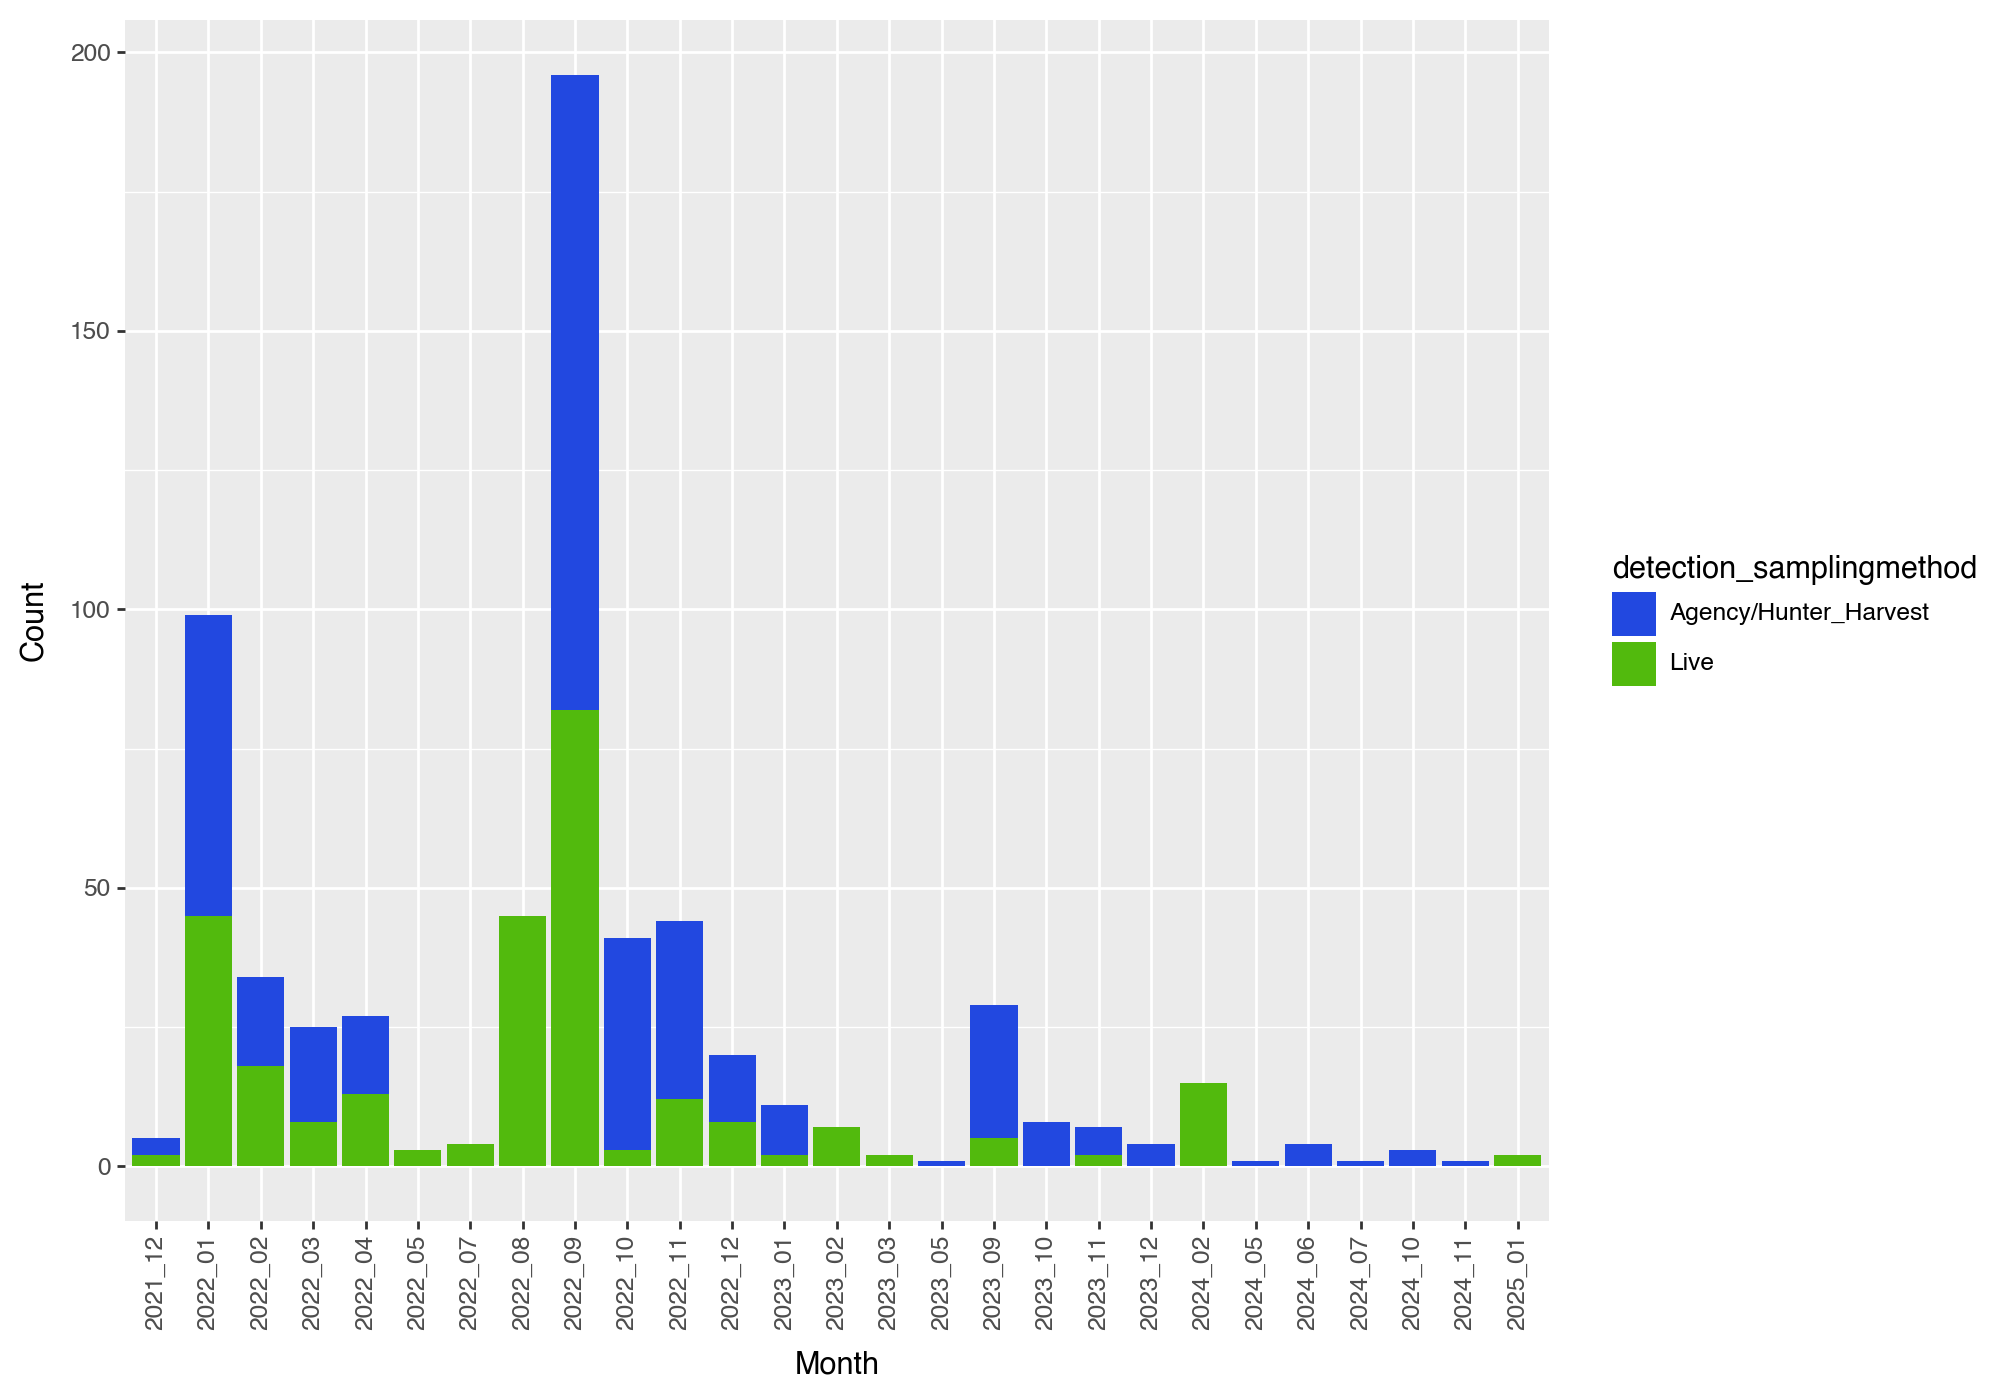

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./metadata/exploratory_data_analysis/live-harvest_sequences.png


In [22]:
sampling_color = {"Dead":"#C72300",
                  "Live":"#52BA0D",
                  "Euthanized":"#FF96F9",
                  "Agency/Hunter_Harvest":"#2248E0"
                 }

plot = (
    ggplot(metadata_liveharvest_mainintro, aes(x = "year_month", fill = "detection_samplingmethod"))
    + geom_bar(stat = "count")
    + scale_fill_manual(sampling_color)
    + labs(x = "Month", y = "Count")
    + theme(axis_text_x=element_text(rotation=90), figure_size = (10, 7))
)

plot.show()
plot.save("./metadata/exploratory_data_analysis/live-harvest_sequences.png", height=10, width=20, units = 'in', dpi=750)

In [23]:
# metadata_with_sampling_method.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_live-harvest-only.tsv", sep = '\t')
metadata_liveharvest_mainintro.to_csv("./BEAST/empirical_trees/submission_files/2026-02-04_main-intro_liveharvest_ha_empirical_targetedbeast/inputs/liveharvest_metadata.tsv", sep = '\t')

In [24]:
# Step three: make a FASTA with corresponding sequences

In [25]:
#Function: Read in the FASTA as a dataframe

def fasta_reader(path_to_fasta, output_name):
    fasta_data = []
    FASTANAME = path_to_fasta
        
    with open(FASTANAME) as f:
        header = ""
        sequence = ""
        for line in f:
            if line.startswith(">"):
                if header != "":
                    fasta_data.append({"header": header, "sequence": sequence})
                header = line.strip() 
                sequence = ""
            else:
                sequence += line.strip()
        fasta_data.append({"header": header, "sequence": sequence}) #last line 
        
    globals()[output_name] = pd.DataFrame(fasta_data)

    return

In [26]:
# Function to write a new fasta with just the sequences in the metadata
# Adapted from Maria

def fasta_writer(path, filename, df):
            
    try:  
        os.mkdir(path)

    except OSError as error:
        pass

    with open(f"{path}{filename}", "w") as f:
        for index, row in df.iterrows():
            f.write(f"{row['header']}\n")
            f.write(f"{row['sequence']}\n")

In [27]:
# Function: remove the carrot from the header

def header_to_strain(df):
    df["strain"] = df["header"].str.replace(">","")

    return(df)

In [28]:
# Function: parse to include

def parse_toinclude(objects_list, file_to_parse):
    # Define the list as the objects to include
    to_include = objects_list

    # Filter rows where the 'taxon' value is in the strains_set
    parsed = file_to_parse[file_to_parse["strain"].isin(to_include)]

    return parsed

In [31]:
# List the strain names

list_of_strains = metadata_liveharvest_mainintro["strain"].to_list()

fasta_reader("./raw_data/ncbi-bvbrc_from-meta_ha.fasta", "ha_fasta")

ha_fasta_strain = header_to_strain(ha_fasta)

parsed_fasta = parse_toinclude(list_of_strains, ha_fasta_strain)

In [32]:
print(len(parsed_fasta))

639


In [33]:
#fasta_writer("./raw_data/", "ncbi-bvbrc-gisaid_live-harvest-only_ha.fasta", parsed_fasta)
fasta_writer("./BEAST/empirical_trees/submission_files/2026-02-04_main-intro_liveharvest_ha_empirical_targetedbeast/inputs", "liveharvest_strains.fasta", parsed_fasta)